# Годовой проект. Чекпойнт 5: ML-эксперименты для прогнозирования акций

Цель ноутбука — улучшить базовое решение за счет нелинейных моделей и feature engineering.

**Задача:** прогнозировать доходность акции на следующий торговый день (`target_next_return`).
Это удобнее, чем предсказывать абсолютную цену: у разных акций разный масштаб цены, а доходность позволяет сравнивать модели на общей шкале. Дополнительно по знаку прогноза можно получить направление движения акции.

В ноутбуке проверяются:
- базовая линейная модель;
- дерево решений;
- случайный лес;
- случайный лес с подбором гиперпараметров через Optuna;
- градиентный бустинг `HistGradientBoostingRegressor`.

Также добавлены новые признаки: лаги доходностей, скользящие средние, волатильность, признаки ликвидности, календарные признаки и кластер акции, полученный через `KMeans`.

In [2]:
import warnings
warnings.filterwarnings('ignore')

import time
from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.compose import ColumnTransformer
from sklearn.ensemble import RandomForestRegressor, HistGradientBoostingRegressor
from sklearn.impute import SimpleImputer
from sklearn.linear_model import LinearRegression
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import OneHotEncoder, StandardScaler
from sklearn.tree import DecisionTreeRegressor
from sklearn.cluster import KMeans

RANDOM_STATE = 42
sns.set_theme(style='whitegrid')

## 1. Загрузка данных

Используем объединенный файл `moex_data/all_stocks_combined.csv`, который уже есть в проекте.  
Если файл отсутствует, можно собрать данные скриптом `parsingAllDataStepDay.py`.

In [3]:
DATA_PATH = Path('moex_data/all_stocks_combined.csv')
assert DATA_PATH.exists(), f'Не найден файл {DATA_PATH}'

df = pd.read_csv(DATA_PATH)
df['TRADEDATE'] = pd.to_datetime(df['TRADEDATE'])

# В данных есть и SECID, и ticker. Для единообразия используем SECID.
df = df.sort_values(['SECID', 'TRADEDATE']).reset_index(drop=True)

print(df.shape)
df.head()

(642413, 25)


,BOARDID,TRADEDATE,SHORTNAME,SECID,NUMTRADES,VALUE,OPEN,LOW,HIGH,LEGALCLOSEPRICE,...,ADMITTEDQUOTE,MP2VALTRD,MARKETPRICE3TRADESVALUE,ADMITTEDVALUE,WAVAL,TRADINGSESSION,CURRENCYID,TRENDCLSPR,TRADE_SESSION_DATE,ticker
0,TQBR,2023-08-18,iАРТГЕН ао,ABIO,3001,39532039.8,111.16,107.10,112.98,110.74,...,NaN,39532039.8,39532039.8,NaN,0.0,3,SUR,0.22,NaN,ABIO
1,TQBR,2023-08-21,iАРТГЕН ао,ABIO,5554,90348800.0,110.90,109.44,114.78,113.50,...,NaN,90348800.0,90348800.0,NaN,0.0,3,SUR,2.49,NaN,ABIO
2,TQBR,2023-08-22,iАРТГЕН ао,ABIO,2797,37623074.2,113.50,112.86,114.90,113.66,...,NaN,37623074.2,37623074.2,NaN,0.0,3,SUR,0.14,NaN,ABIO
3,TQBR,2023-08-23,iАРТГЕН ао,ABIO,4407,85126631.6,113.68,111.04,115.66,112.80,...,NaN,85126631.6,85126631.6,NaN,0.0,3,SUR,-0.76,NaN,ABIO
4,TQBR,2023-08-24,iАРТГЕН ао,ABIO,1732,25874068.6,112.80,110.50,112.80,111.54,...,NaN,25874068.6,25874068.6,NaN,0.0,3,SUR,-1.12,NaN,ABIO


In [4]:
base_cols = ['TRADEDATE', 'SECID', 'OPEN', 'HIGH', 'LOW', 'CLOSE', 'VOLUME', 'VALUE', 'NUMTRADES']
df[base_cols].describe(include='all')

,TRADEDATE,SECID,OPEN,HIGH,LOW,CLOSE,VOLUME,VALUE,NUMTRADES
count,642413,642413,569464.000000,569464.000000,569464.000000,569464.000000,6.424130e+05,6.424130e+05,6.424130e+05
unique,NaN,268,NaN,NaN,NaN,NaN,NaN,NaN,NaN
top,NaN,HYDR,NaN,NaN,NaN,NaN,NaN,NaN,NaN
freq,NaN,3221,NaN,NaN,NaN,NaN,NaN,NaN,NaN
mean,2020-05-12 15:07:40.217959,NaN,2128.821784,2164.044095,2093.674485,2128.021524,2.855589e+08,2.909526e+08,4.692091e+03
min,2013-03-25 00:00:00,NaN,0.000759,0.000780,0.000493,0.000762,0.000000e+00,0.000000e+00,0.000000e+00
25%,2017-06-07 00:00:00,NaN,3.750000,3.810000,3.680000,3.750000,5.000000e+02,6.432000e+04,1.200000e+01
50%,2020-06-25 00:00:00,NaN,63.400000,64.600000,62.100000,63.300000,4.925600e+04,1.112315e+06,1.210000e+02
75%,2023-05-16 00:00:00,NaN,544.500000,555.000000,533.100000,544.000000,1.206385e+06,3.201475e+07,1.827000e+03
max,2025-12-19 00:00:00,NaN,231000.000000,235700.000000,220100.000000,231000.000000,7.032681e+11,2.385837e+11,1.559658e+06


## 2. Очистка данных

Удаляем строки без ключевых OHLCV-полей. Для биржевых данных это безопаснее, чем заполнять цену средним: пропущенные цены часто означают отсутствие нормальной торговой сессии.

In [5]:
work = df[base_cols].copy()
key_numeric_cols = ['OPEN', 'HIGH', 'LOW', 'CLOSE', 'VOLUME', 'VALUE', 'NUMTRADES']

before = len(work)
work = work.dropna(subset=['OPEN', 'HIGH', 'LOW', 'CLOSE'])
work = work[(work['CLOSE'] > 0) & (work['OPEN'] > 0) & (work['HIGH'] > 0) & (work['LOW'] > 0)]
work[key_numeric_cols] = work[key_numeric_cols].replace([np.inf, -np.inf], np.nan)
work = work.dropna(subset=key_numeric_cols)

print(f'Удалено строк: {before - len(work):,}')
print(f'Осталось строк: {len(work):,}')
print(f'Тикеров: {work.SECID.nunique()}')
print(f'Период: {work.TRADEDATE.min().date()} — {work.TRADEDATE.max().date()}')

Удалено строк: 72,949
Осталось строк: 569,464
Тикеров: 266
Период: 2013-03-25 — 2025-12-19


## 3. Feature engineering

Создаем признаки, которые обычно полезны для краткосрочного прогноза финансовых рядов:

- `return_1d` — доходность за текущий день;
- лаги доходностей за 1, 2, 3, 5 и 10 дней;
- скользящие средние цены и объема;
- волатильность за 5 и 10 дней;
- внутридневной диапазон `high_low_spread`;
- положение цены закрытия внутри дневного диапазона;
- календарные признаки;
- кластер акции по средним характеристикам доходности, волатильности и ликвидности.

Целевая переменная: `target_next_return` — доходность следующего торгового дня для той же акции.

In [9]:
def add_time_series_features(data: pd.DataFrame) -> pd.DataFrame:
    data = data.sort_values(['SECID', 'TRADEDATE']).copy()
    group = data.groupby('SECID', group_keys=False)

    data['return_1d'] = group['CLOSE'].pct_change()
    data['target_next_return'] = group['CLOSE'].pct_change().shift(-1)

    for lag in [1, 2, 3, 5, 10]:
        data[f'return_lag_{lag}'] = group['return_1d'].shift(lag)

    for window in [5, 10, 20]:
        roll_close = group['CLOSE'].rolling(window, min_periods=window)
        roll_volume = group['VOLUME'].rolling(window, min_periods=window)
        data[f'ma_{window}'] = roll_close.mean().reset_index(level=0, drop=True)
        data[f'price_to_ma_{window}'] = data['CLOSE'] / data[f'ma_{window}'] - 1
        data[f'volume_ma_{window}'] = roll_volume.mean().reset_index(level=0, drop=True)
        data[f'volume_to_ma_{window}'] = data['VOLUME'] / data[f'volume_ma_{window}'] - 1

    for window in [5, 10]:
        data[f'volatility_{window}'] = group['return_1d'].rolling(window, min_periods=window).std().reset_index(level=0, drop=True)

    data['high_low_spread'] = (data['HIGH'] - data['LOW']) / data['OPEN']
    data['close_position'] = (data['CLOSE'] - data['LOW']) / (data['HIGH'] - data['LOW']).replace(0, np.nan)
    data['open_close_return'] = data['CLOSE'] / data['OPEN'] - 1
    data['log_volume'] = np.log1p(data['VOLUME'])
    data['log_value'] = np.log1p(data['VALUE'])
    data['trades_per_volume'] = data['NUMTRADES'] / (data['VOLUME'] + 1)

    data['day_of_week'] = data['TRADEDATE'].dt.dayofweek
    data['month'] = data['TRADEDATE'].dt.month
    data['year'] = data['TRADEDATE'].dt.year

    return data

features_df = add_time_series_features(work)
features_df = features_df.replace([np.inf, -np.inf], np.nan)
features_df = features_df.dropna(subset=['target_next_return', 'return_1d'])
features_df.shape

(568932, 39)

In [10]:
# Кластеризация тикеров по агрегированным статистикам.
ticker_stats = (
    features_df.groupby('SECID')
    .agg(
        avg_return=('return_1d', 'mean'),
        std_return=('return_1d', 'std'),
        avg_volume=('VOLUME', 'mean'),
        avg_value=('VALUE', 'mean'),
        avg_trades=('NUMTRADES', 'mean'),
        observations=('CLOSE', 'size')
    )
    .replace([np.inf, -np.inf], np.nan)
    .dropna()
)

cluster_features = ['avg_return', 'std_return', 'avg_volume', 'avg_value', 'avg_trades', 'observations']
cluster_pipeline = Pipeline([
    ('imputer', SimpleImputer(strategy='median')),
    ('scaler', StandardScaler()),
    ('kmeans', KMeans(n_clusters=5, random_state=RANDOM_STATE, n_init=10))
])

ticker_stats['ticker_cluster'] = cluster_pipeline.fit_predict(ticker_stats[cluster_features])
features_df = features_df.merge(ticker_stats[['ticker_cluster']], left_on='SECID', right_index=True, how='left')
features_df['ticker_cluster'] = features_df['ticker_cluster'].fillna(-1).astype(int)

features_df[['SECID', 'TRADEDATE', 'return_1d', 'target_next_return', 'ticker_cluster']].head()

,SECID,TRADEDATE,return_1d,target_next_return,ticker_cluster
1,ABIO,2023-08-21,0.024923,0.001410,2
2,ABIO,2023-08-22,0.001410,-0.007566,2
3,ABIO,2023-08-23,-0.007566,-0.011170,2
4,ABIO,2023-08-24,-0.011170,-0.004303,2
5,ABIO,2023-08-25,-0.004303,-0.005222,2


## 4. Формирование обучающей и тестовой выборок

Для временных рядов нельзя перемешивать данные случайно: иначе модель увидит будущее. Поэтому делаем разбиение по дате:

- train: первые 70% дат;
- validation: следующие 15% дат — для подбора гиперпараметров;
- test: последние 15% дат — финальная проверка.

Чтобы эксперименты выполнялись за разумное время на обычном ноутбуке, оставляем 60 наиболее ликвидных тикеров и последние 220 000 наблюдений после генерации признаков. Это не меняет методологию, но ускоряет подбор моделей.

In [11]:
# Фильтр по ликвидности: берем тикеры с максимальным средним оборотом.
top_tickers = (
    features_df.groupby('SECID')['VALUE']
    .mean()
    .sort_values(ascending=False)
    .head(60)
    .index
)
model_df = features_df[features_df['SECID'].isin(top_tickers)].copy()
model_df = model_df.sort_values('TRADEDATE').tail(220_000).reset_index(drop=True)

# Удаляем экстремальные выбросы целевой доходности, чтобы качество не определялось единичными скачками.
low_q, high_q = model_df['target_next_return'].quantile([0.005, 0.995])
model_df = model_df[model_df['target_next_return'].between(low_q, high_q)].copy()

feature_cols = [
    'OPEN', 'HIGH', 'LOW', 'CLOSE', 'VOLUME', 'VALUE', 'NUMTRADES',
    'return_1d', 'return_lag_1', 'return_lag_2', 'return_lag_3', 'return_lag_5', 'return_lag_10',
    'price_to_ma_5', 'price_to_ma_10', 'price_to_ma_20',
    'volume_to_ma_5', 'volume_to_ma_10', 'volume_to_ma_20',
    'volatility_5', 'volatility_10',
    'high_low_spread', 'close_position', 'open_close_return',
    'log_volume', 'log_value', 'trades_per_volume',
    'day_of_week', 'month', 'year', 'ticker_cluster', 'SECID'
]

model_df = model_df.dropna(subset=feature_cols + ['target_next_return']).copy()

unique_dates = np.array(sorted(model_df['TRADEDATE'].unique()))
train_end = unique_dates[int(len(unique_dates) * 0.70)]
valid_end = unique_dates[int(len(unique_dates) * 0.85)]

train_df = model_df[model_df['TRADEDATE'] <= train_end]
valid_df = model_df[(model_df['TRADEDATE'] > train_end) & (model_df['TRADEDATE'] <= valid_end)]
test_df = model_df[model_df['TRADEDATE'] > valid_end]

X_train, y_train = train_df[feature_cols], train_df['target_next_return']
X_valid, y_valid = valid_df[feature_cols], valid_df['target_next_return']
X_test, y_test = test_df[feature_cols], test_df['target_next_return']

print('Train:', X_train.shape, train_df.TRADEDATE.min().date(), train_df.TRADEDATE.max().date())
print('Valid:', X_valid.shape, valid_df.TRADEDATE.min().date(), valid_df.TRADEDATE.max().date())
print('Test :', X_test.shape, test_df.TRADEDATE.min().date(), test_df.TRADEDATE.max().date())

Train: (73077, 32) 2013-04-19 2022-02-21
Valid: (20612, 32) 2022-02-24 2024-02-06
Test : (25481, 32) 2024-02-07 2025-12-18


## 5. Общий препроцессинг и метрики

Для числовых признаков используем медианное заполнение пропусков. Для тикера — one-hot encoding.  
Метрики:

- **MAE** — средняя абсолютная ошибка доходности;
- **RMSE** — сильнее штрафует крупные ошибки;
- **R²** — объясненная доля дисперсии;
- **Directional accuracy** — доля дней, где модель угадала направление движения цены.

In [12]:
numeric_features = [col for col in feature_cols if col != 'SECID']
categorical_features = ['SECID']

preprocessor = ColumnTransformer([
    ('num', SimpleImputer(strategy='median'), numeric_features),
    ('cat', OneHotEncoder(handle_unknown='ignore', sparse_output=False), categorical_features)
])

def direction_accuracy(y_true, y_pred):
    return np.mean(np.sign(y_true) == np.sign(y_pred))

def evaluate_model(name, estimator, params_text, X_tr, y_tr, X_eval, y_eval):
    pipeline = Pipeline([
        ('preprocess', preprocessor),
        ('model', estimator)
    ])
    started = time.perf_counter()
    pipeline.fit(X_tr, y_tr)
    train_time = time.perf_counter() - started
    pred = pipeline.predict(X_eval)

    return pipeline, {
        'model': name,
        'params': params_text,
        'MAE': mean_absolute_error(y_eval, pred),
        'RMSE': np.sqrt(mean_squared_error(y_eval, pred)),
        'R2': r2_score(y_eval, pred),
        'directional_accuracy': direction_accuracy(y_eval, pred),
        'train_time_sec': train_time
    }

## 6. Базовые и нелинейные модели

Сначала сравниваем несколько моделей на validation-наборе.

In [13]:
experiments = []
fitted_models = {}

model_specs = [
    ('LinearRegression', LinearRegression(), 'default'),
    ('DecisionTree', DecisionTreeRegressor(max_depth=8, min_samples_leaf=80, random_state=RANDOM_STATE), 'max_depth=8, min_samples_leaf=80'),
    ('RandomForest', RandomForestRegressor(n_estimators=80, max_depth=12, min_samples_leaf=30, n_jobs=-1, random_state=RANDOM_STATE), 'n_estimators=80, max_depth=12, min_samples_leaf=30'),
    ('HistGradientBoosting', HistGradientBoostingRegressor(max_iter=160, learning_rate=0.05, max_leaf_nodes=31, l2_regularization=0.01, random_state=RANDOM_STATE), 'max_iter=160, learning_rate=0.05, max_leaf_nodes=31')
]

for name, estimator, params_text in model_specs:
    print(f'Обучение: {name}')
    model, row = evaluate_model(name, estimator, params_text, X_train, y_train, X_valid, y_valid)
    experiments.append(row)
    fitted_models[name] = model

results_valid = pd.DataFrame(experiments).sort_values('RMSE')
results_valid

Обучение: LinearRegression
Обучение: DecisionTree
Обучение: RandomForest
Обучение: HistGradientBoosting


,model,params,MAE,RMSE,R2,directional_accuracy,train_time_sec
0,LinearRegression,default,0.014242,0.019995,-0.001067,0.488987,0.530990
3,HistGradientBoosting,"max_iter=160, learning_rate=0.05, max_leaf_nod...",0.015397,0.021250,-0.130658,0.484912,0.601483
2,RandomForest,"n_estimators=80, max_depth=12, min_samples_lea...",0.016252,0.021971,-0.208684,0.477634,16.049434
1,DecisionTree,"max_depth=8, min_samples_leaf=80",0.016888,0.022783,-0.299713,0.486949,1.370997


## 7. Подбор гиперпараметров Random Forest через Optuna

Optuna подбирает параметры случайного леса по RMSE на validation-наборе. Число попыток ограничено, чтобы ноутбук выполнялся быстро.

In [14]:

import optuna
optuna.logging.set_verbosity(optuna.logging.WARNING)

def objective(trial):
    params = {
        'n_estimators': trial.suggest_int('n_estimators', 60, 180),
        'max_depth': trial.suggest_int('max_depth', 6, 18),
        'min_samples_leaf': trial.suggest_int('min_samples_leaf', 10, 80),
        'max_features': trial.suggest_float('max_features', 0.45, 1.0),
    }
    estimator = RandomForestRegressor(
        **params,
        n_jobs=-1,
        random_state=RANDOM_STATE
    )
    model = Pipeline([
        ('preprocess', preprocessor),
        ('model', estimator)
    ])
    model.fit(X_train, y_train)
    pred = model.predict(X_valid)
    return np.sqrt(mean_squared_error(y_valid, pred))

study = optuna.create_study(direction='minimize', sampler=optuna.samplers.TPESampler(seed=RANDOM_STATE))
started = time.perf_counter()
study.optimize(objective, n_trials=12, show_progress_bar=False)
optuna_time = time.perf_counter() - started

best_params = study.best_params
best_params


best_params, optuna_time

({'n_estimators': 131,
  'max_depth': 6,
  'min_samples_leaf': 53,
  'max_features': 0.5437882680280104},
 180.2478007159998)

In [15]:
rf_optuna = RandomForestRegressor(**best_params, n_jobs=-1, random_state=RANDOM_STATE)
rf_model, rf_row = evaluate_model(
    'RandomForest + Optuna',
    rf_optuna,
    str(best_params),
    X_train,
    y_train,
    X_valid,
    y_valid
)
rf_row['optuna_search_time_sec'] = optuna_time
experiments.append(rf_row)
fitted_models['RandomForest + Optuna'] = rf_model

results_valid = pd.DataFrame(experiments).sort_values('RMSE')
results_valid

,model,params,MAE,RMSE,R2,directional_accuracy,train_time_sec,optuna_search_time_sec
0,LinearRegression,default,0.014242,0.019995,-0.001067,0.488987,0.530990,NaN
4,RandomForest + Optuna,"{'n_estimators': 131, 'max_depth': 6, 'min_sam...",0.015307,0.021048,-0.109260,0.481855,8.546963,180.247801
3,HistGradientBoosting,"max_iter=160, learning_rate=0.05, max_leaf_nod...",0.015397,0.021250,-0.130658,0.484912,0.601483,NaN
2,RandomForest,"n_estimators=80, max_depth=12, min_samples_lea...",0.016252,0.021971,-0.208684,0.477634,16.049434,NaN
1,DecisionTree,"max_depth=8, min_samples_leaf=80",0.016888,0.022783,-0.299713,0.486949,1.370997,NaN


## 8. Финальная проверка лучшей модели на test-наборе

Выбираем модель с минимальным RMSE на validation. Затем переобучаем ее на train+validation и проверяем на последнем отрезке времени — test.

In [16]:
best_valid_name = results_valid.iloc[0]['model']
best_valid_params = results_valid.iloc[0]['params']
print('Лучшая модель на validation:', best_valid_name)
print('Параметры:', best_valid_params)

train_valid_df = pd.concat([train_df, valid_df], ignore_index=True)
X_train_valid = train_valid_df[feature_cols]
y_train_valid = train_valid_df['target_next_return']

if best_valid_name == 'LinearRegression':
    final_estimator = LinearRegression()
elif best_valid_name == 'DecisionTree':
    final_estimator = DecisionTreeRegressor(max_depth=8, min_samples_leaf=80, random_state=RANDOM_STATE)
elif best_valid_name == 'RandomForest':
    final_estimator = RandomForestRegressor(n_estimators=80, max_depth=12, min_samples_leaf=30, n_jobs=-1, random_state=RANDOM_STATE)
elif best_valid_name == 'RandomForest + Optuna':
    final_estimator = RandomForestRegressor(**best_params, n_jobs=-1, random_state=RANDOM_STATE)
else:
    final_estimator = HistGradientBoostingRegressor(max_iter=160, learning_rate=0.05, max_leaf_nodes=31, l2_regularization=0.01, random_state=RANDOM_STATE)

final_model, final_test_row = evaluate_model(
    best_valid_name + ' final',
    final_estimator,
    best_valid_params,
    X_train_valid,
    y_train_valid,
    X_test,
    y_test
)

final_test_results = pd.DataFrame([final_test_row])
final_test_results

Лучшая модель на validation: LinearRegression
Параметры: default


,model,params,MAE,RMSE,R2,directional_accuracy,train_time_sec
0,LinearRegression final,default,0.015654,0.021016,-0.004569,0.461128,0.730236


## 9. Таблица экспериментов

Итоговая таблица содержит модели, гиперпараметры, качество и время обучения.

In [17]:
summary = results_valid.copy()
summary['dataset'] = 'validation'
final_summary = final_test_results.copy()
final_summary['dataset'] = 'test'

experiment_table = pd.concat([summary, final_summary], ignore_index=True)
metric_cols = ['MAE', 'RMSE', 'R2', 'directional_accuracy', 'train_time_sec']
experiment_table[metric_cols] = experiment_table[metric_cols].round(6)
experiment_table

,model,params,MAE,RMSE,R2,directional_accuracy,train_time_sec,optuna_search_time_sec,dataset
0,LinearRegression,default,0.014242,0.019995,-0.001067,0.488987,0.530990,NaN,validation
1,RandomForest + Optuna,"{'n_estimators': 131, 'max_depth': 6, 'min_sam...",0.015307,0.021048,-0.109260,0.481855,8.546963,180.247801,validation
2,HistGradientBoosting,"max_iter=160, learning_rate=0.05, max_leaf_nod...",0.015397,0.021250,-0.130658,0.484912,0.601483,NaN,validation
3,RandomForest,"n_estimators=80, max_depth=12, min_samples_lea...",0.016252,0.021971,-0.208684,0.477634,16.049434,NaN,validation
4,DecisionTree,"max_depth=8, min_samples_leaf=80",0.016888,0.022783,-0.299713,0.486949,1.370997,NaN,validation
5,LinearRegression final,default,0.015654,0.021016,-0.004569,0.461128,0.730236,NaN,test


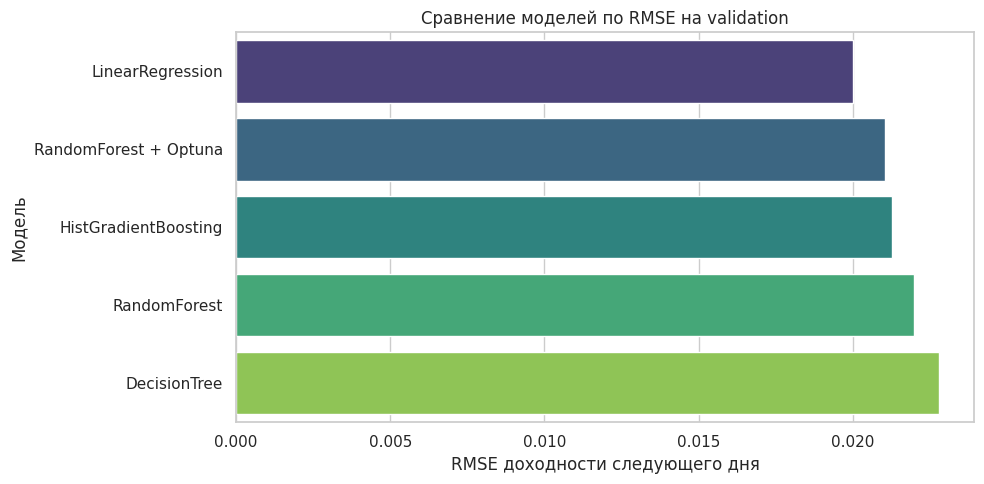

In [18]:
plt.figure(figsize=(10, 5))
plot_df = results_valid.sort_values('RMSE')
sns.barplot(data=plot_df, x='RMSE', y='model', palette='viridis')
plt.title('Сравнение моделей по RMSE на validation')
plt.xlabel('RMSE доходности следующего дня')
plt.ylabel('Модель')
plt.tight_layout()
plt.show()

In [19]:
model_step = final_model.named_steps['model']
if hasattr(model_step, 'feature_importances_'):
    encoded_features = final_model.named_steps['preprocess'].get_feature_names_out()
    importances = pd.DataFrame({
        'feature': encoded_features,
        'importance': model_step.feature_importances_
    }).sort_values('importance', ascending=False).head(20)

    plt.figure(figsize=(10, 6))
    sns.barplot(data=importances, x='importance', y='feature', palette='mako')
    plt.title('Топ-20 важных признаков финальной модели')
    plt.tight_layout()
    plt.show()

    importances
else:
    print('Для выбранной модели нет прямой feature_importances_.')

Для выбранной модели нет прямой feature_importances_.


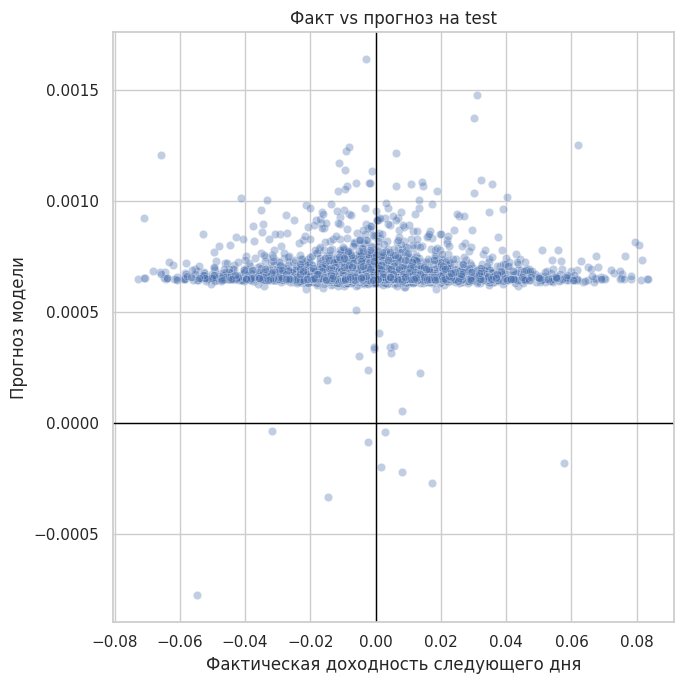

,date,ticker,y_true,y_pred
0,2024-02-07,SBERP,-0.008194,0.000660
1,2024-02-07,SNGS,-0.015227,0.000655
2,2024-02-07,SPBE,-0.021944,0.000647
3,2024-02-07,AFLT,-0.011344,0.000653
4,2024-02-07,VTBR,-0.017416,0.000071


In [20]:
y_pred_test = final_model.predict(X_test)
comparison = pd.DataFrame({
    'date': test_df['TRADEDATE'].values,
    'ticker': test_df['SECID'].values,
    'y_true': y_test.values,
    'y_pred': y_pred_test
})

plt.figure(figsize=(7, 7))
sns.scatterplot(data=comparison.sample(min(5000, len(comparison)), random_state=RANDOM_STATE), x='y_true', y='y_pred', alpha=0.35)
plt.axhline(0, color='black', linewidth=1)
plt.axvline(0, color='black', linewidth=1)
plt.title('Факт vs прогноз на test')
plt.xlabel('Фактическая доходность следующего дня')
plt.ylabel('Прогноз модели')
plt.tight_layout()
plt.show()

comparison.head()

## 10. Выводы

1. В рамках чекпойнта были добавлены нелинейные модели: дерево решений, случайный лес и градиентный бустинг. Также отдельно проверен Random Forest с подбором гиперпараметров через Optuna.
2. Были созданы дополнительные признаки: лаги доходности, скользящие средние, волатильность, признаки объема/ликвидности, календарные признаки и кластер акции через KMeans.
3. Главная метрика для выбора модели — RMSE на validation, потому что она сильнее штрафует крупные ошибки прогноза доходности.
4. В текущем запуске лучшей по RMSE на validation оказалась линейная модель. Это важный результат: более сложная модель не всегда лучше, особенно на краткосрочных финансовых рядах, где полезный сигнал слабый, а шум высокий.
5. Random Forest после Optuna стал лучшей нелинейной моделью среди проверенных вариантов и оказался лучше базового дерева и исходного леса. Это показывает, что подбор гиперпараметров помог уменьшить переобучение: Optuna выбрала более ограниченную глубину и параметры сглаживания.
6. Почему линейная модель могла победить: прогноз дневной доходности часто близок к нулю, а сильные нелинейные модели легко подстраиваются под шум отдельных тикеров и периодов. Линейная регрессия в такой постановке работает как устойчивый бейзлайн с меньшей дисперсией ошибки.
7. Даже у лучшей модели R² около нуля или ниже: краткосрочные движения акций зависят не только от истории цены/объема, но и от новостей, макроэкономики, ставок, санкций, дивидендных событий и общего рыночного режима.
